# Final Examination: TranslateAI Ancient Character Recognition

Total Marks: 100

**Instructions:**
1. Enter your course email in the cell below.
2. Read the story and problem descriptions carefully.
3. Complete the code in cells containing `# YOUR CODE HERE`. Do not modify the test cells.
4. Run all cells sequentially to ensure your tests pass before submitting.

In [ ]:
# Enter your course email here
student_email = "md.faisalmia994@gmail.com" # Example: "your.name@university.edu"
print(f"Name : {student_email}")

Name : md.faisalmia994@gmail.com


---

## 📖 TranslateAI — Digitizing History

You have just been hired as a Machine Learning Engineer at **TranslateAI**, a startup working with international museums. Your first task is to build a neural network that can automatically classify ancient Japanese cursive texts.

We will use the **KMNIST** dataset — 28x28 grayscale images of 10 cursive characters: *o, ki, su, tsu, na, ha, ma, ya, re, wo*.

To ensure top performance, you must optimize your deep learning pipeline using **Batch Normalization** and **Advanced Optimizers (Adam)**.

---

## Question 1: Load, Explore, & Preprocess Data (20 Marks)

### 1.1 Download the Dataset (5 Marks)

We will use `torchvision.datasets.KMNIST` to download the dataset.

Run the cell below to download the training and test sets:

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torchvision
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Class names for KMNIST
class_names = ['o', 'ki', 'su', 'tsu', 'na', 'ha', 'ma', 'ya', 're', 'wo']

# Download KMNIST
full_train_dataset = torchvision.datasets.KMNIST(root='./data', train=True, download=True)
test_dataset_raw = torchvision.datasets.KMNIST(root='./data', train=False, download=True)

print(f"Training set size: {len(full_train_dataset)}")
print(f"Test set size: {len(test_dataset_raw)}")

Training set size: 60000
Test set size: 10000


In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


### 1.2 Visualize Sample Grayscale Images (5 Marks)

Create a **2x5 subplot figure** (figsize 12x5) showing one sample image from **each of the 10 classes**.
- Title each subplot with its class name
- Turn off axis ticks
- Ensure you use `cmap='gray'` for visualization.

In [ ]:
print(full_train_dataset.classes)

['o', 'ki', 'su', 'tsu', 'na', 'ha', 'ma', 'ya', 're', 'wo']


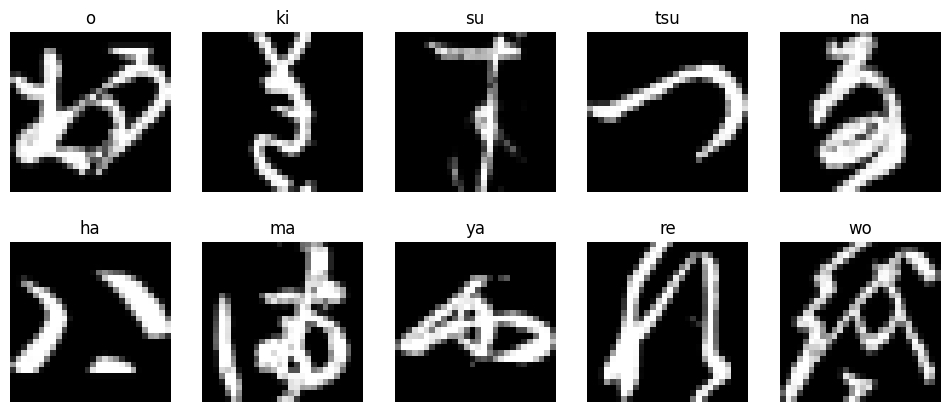

In [ ]:
# YOUR CODE
import matplotlib.pyplot as plt

fig,axes = plt.subplots(2,5,figsize=(12,5))
axes = axes.flatten()

for i in range(10):
  idx = np.where(full_train_dataset.targets == i)[0][0]
  img,label = full_train_dataset[idx]

  axes[i].imshow(img,cmap='gray')
  axes[i].set_title(class_names[i])
  axes[i].axis('off')
plt.show()

### 1.3 Data Scaling & Splitting (10 Marks)

**Your tasks:**
1. Extract images and labels from both train and test datasets as NumPy arrays. (Note: KMNIST images are 28x28)
2. Normalize the pixel values to the range [0, 1] by MinMax Scaling.
3. Split the training data into **train (50,000)** and **validation (10,000)** using `train_test_split` with `random_state=42`.
4. Convert all sets to PyTorch tensors — images as `float32`, labels as `long`.

**Required variables:** `X_train, X_val, X_test` (float32 tensors), `y_train, y_val, y_test` (long tensors)

In [ ]:
from sklearn.preprocessing import MinMaxScaler
# YOUR CODE HERE

train_images_all = full_train_dataset.data.numpy()
train_labels_all = full_train_dataset.targets.numpy()
test_images_all = test_dataset_raw.data.numpy()
test_labels_all = test_dataset_raw.targets.numpy()

scaler = MinMaxScaler()

train_images_all = scaler.fit_transform(train_images_all.reshape(-1,28*28)).reshape(-1,28,28)
test_images_all = scaler.transform(test_images_all.reshape(-1,28*28)).reshape(-1,28,28)

X_train,X_val,y_train,y_val = train_test_split(train_images_all,train_labels_all,test_size=10000,random_state=42)

X_train = torch.tensor(X_train,dtype=torch.float32)
y_train = torch.tensor(y_train,dtype=torch.long)

X_val = torch.tensor(X_val,dtype=torch.float32)
y_val = torch.tensor(y_val,dtype=torch.long)

X_test = torch.tensor(test_images_all,dtype=torch.float32)
y_test = torch.tensor(test_labels_all,dtype=torch.long)

In [ ]:
# --- TEST CELL (DO NOT MODIFY) ---
assert X_train.shape == (50000, 28, 28), f"Expected (50000, 28, 28), got {X_train.shape}"
assert X_val.shape == (10000, 28, 28)
assert X_train.dtype == torch.float32
assert y_train.dtype == torch.long
print("✅ Q1.3 Passed!")

✅ Q1.3 Passed!


---

## Question 2: Build PyTorch DataLoaders (15 Marks)

Create `TensorDataset` and `DataLoader` objects for train, validation, and test sets.

- **batch_size = 256**
- **shuffle = True** for training, **False** for validation and test

**Required variables:** `train_loader`, `val_loader`, `test_loader`

In [ ]:
# YOUR CODE HERE

train_dataset = TensorDataset(X_train,y_train)
val_dataset = TensorDataset(X_val,y_val)
test_dataset = TensorDataset(X_test,y_test)

train_loader = DataLoader(train_dataset,batch_size=256,shuffle=True)
val_loader = DataLoader(val_dataset,batch_size=256,shuffle=False)
test_loader = DataLoader(test_dataset,batch_size=256,shuffle=False)

In [ ]:
# --- TEST CELL (DO NOT MODIFY) ---
batch_X, batch_y = next(iter(train_loader))
assert batch_X.shape == (256, 28, 28)
assert batch_y.dtype == torch.long
print("✅ Q2 Passed!")

✅ Q2 Passed!


---

## Question 3: Deep Neural Network Architecture (25 Marks)

Create a class `TranslateAIClassifier` inheriting from `nn.Module`.

Use `nn.Sequential` with this architecture. Since the input is `28x28`, the flattened size is **784**.

| Layer | Description |
|-------|-------------|
| Flatten | Convert 28x28 → 784 |
| Linear | 784 → 512 |
| BatchNorm1d | Batch Normalization (512 features) |
| ReLU | Activation |
| Linear | 512 → 256 |
| BatchNorm1d | Batch Normalization (256 features) |
| ReLU | Activation |
| Linear | 256 → 128 |
| BatchNorm1d | Batch Normalization (128 features) |
| ReLU | Activation |
| Linear | 128 → 10 |

After defining the class, create an instance called `model` and print it.

In [ ]:
# YOUR CODE
class TranslateAIClassifier(nn.Module):
  def __init__(self,input_size,num_classes):
    super().__init__()

    self.model = nn.Sequential(
        nn.Flatten(),
        nn.Linear(input_size,512),
        nn.BatchNorm1d(512),
        nn.ReLU(),

        nn.Linear(512,256),
        nn.BatchNorm1d(256),
        nn.ReLU(),

        nn.Linear(256,128),
        nn.BatchNorm1d(128),
        nn.ReLU(),

        nn.Linear(128,num_classes)
    )

  def forward(self,features):
    return self.model(features)

model = TranslateAIClassifier(input_size=28*28,num_classes=10)
print(model)

TranslateAIClassifier(
  (model): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Linear(in_features=256, out_features=128, bias=True)
    (8): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
    (10): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [ ]:
# --- TEST CELL (DO NOT MODIFY) ---
test_input = torch.randn(5, 28, 28)
test_output = model(test_input)
assert test_output.shape == (5, 10)
has_batchnorm = any(isinstance(m, nn.BatchNorm1d) for m in model.modules())
assert has_batchnorm, "Model must include BatchNorm1d layers"
print("✅ Q3 Passed!")

✅ Q3 Passed!


---

## Question 4: Advanced Training Pipeline (25 Marks)

### 4.1 Setup Optimizer and Loss (5 Marks)
- Loss function: `nn.CrossEntropyLoss`
- Optimizer: `optim.Adam` with `lr=0.001`
- Number of epochs: **15**

In [ ]:
# YOUR CODE HERE

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(),lr=0.001)
epochs = 15

### 4.2 PyTorch Training Pipeline (20 Marks)

Write the training loop for **15 epochs**.

For each epoch:
1. Set model to training mode (`model.train()`)
2. Train on `train_loader` (forward pass, calculate loss, backward pass, optimizer step)
3. Set model to evaluation mode (`model.eval()`)
4. Evaluate on `val_loader` and compute validation loss and accuracy.
5. Print: `Epoch {epoch+1}/{epochs} | Train Loss: {:.4f} | Val Loss: {:.4f}`

Store: `train_losses`, `val_losses` lists.

In [ ]:
# YOUR CODE HERE

train_losses = []
val_losses = []

for epoch in range(epochs):
  model.train()
  total_epoch_loss = 0
  for batch_features,batch_labels in train_loader:
    batch_features,batch_labels = batch_features.to(device),batch_labels.to(device)

    outputs = model(batch_features)

    loss = criterion(outputs,batch_labels)

    optimizer.zero_grad()
    loss.backward()

    optimizer.step()

    total_epoch_loss += loss.item()
  avg_loss = total_epoch_loss/len(train_loader)
  train_losses.append(avg_loss)

  model.eval()

  total_val_loss = 0.0
  total = 0.0
  correct = 0.0

  with torch.no_grad():
    for batch_features,batch_labels in val_loader:
      batch_features,batch_labels = batch_features.to(device),batch_labels.to(device)

      outputs = model(batch_features)

      loss = criterion(outputs,batch_labels)
      total_val_loss += loss.item()

      _,predicted = torch.max(outputs,1)
      total += batch_labels.shape[0]
      correct += (predicted == batch_labels).sum().item()
  avg_val_loss = total_val_loss/len(val_loader)
  val_losses.append(avg_val_loss)

  val_accuracy = correct/total
  print(f'Epoch: {epoch + 1} Train Loss: {avg_loss:.4f} | Val Loss:{avg_val_loss:.4f} | Val Accuracy:{val_accuracy:.4f}')

Epoch: 1 Train Loss: 0.3826 | Val Loss:0.1793 | Val Accuracy:0.9454
Epoch: 2 Train Loss: 0.1343 | Val Loss:0.1524 | Val Accuracy:0.9503
Epoch: 3 Train Loss: 0.0811 | Val Loss:0.1333 | Val Accuracy:0.9577
Epoch: 4 Train Loss: 0.0526 | Val Loss:0.1289 | Val Accuracy:0.9600
Epoch: 5 Train Loss: 0.0356 | Val Loss:0.1306 | Val Accuracy:0.9603
Epoch: 6 Train Loss: 0.0281 | Val Loss:0.1325 | Val Accuracy:0.9631
Epoch: 7 Train Loss: 0.0218 | Val Loss:0.1497 | Val Accuracy:0.9601
Epoch: 8 Train Loss: 0.0202 | Val Loss:0.1444 | Val Accuracy:0.9613
Epoch: 9 Train Loss: 0.0169 | Val Loss:0.1490 | Val Accuracy:0.9605
Epoch: 10 Train Loss: 0.0130 | Val Loss:0.1529 | Val Accuracy:0.9604
Epoch: 11 Train Loss: 0.0094 | Val Loss:0.1404 | Val Accuracy:0.9630
Epoch: 12 Train Loss: 0.0175 | Val Loss:0.1693 | Val Accuracy:0.9558
Epoch: 13 Train Loss: 0.0164 | Val Loss:0.1403 | Val Accuracy:0.9632
Epoch: 14 Train Loss: 0.0160 | Val Loss:0.1502 | Val Accuracy:0.9635
Epoch: 15 Train Loss: 0.0089 | Val Loss:0.1

In [ ]:
# --- TEST CELL (DO NOT MODIFY) ---
assert len(train_losses) == 15, f"Expected 15 epochs, got {len(train_losses)}"
assert len(val_losses) == 15
print("✅ Q4.2 Passed!")

✅ Q4.2 Passed!


---

## Question 5: Evaluation & Analytics (15 Marks)

### 5.1 Test Evaluation (5 Marks)
Evaluate the model on the **test set**.
- Print the Test Accuracy.
- Collect Test dataset's all predictions into a list called `all_preds`.

In [ ]:
# YOUR CODE HERE

total = 0.0
correct = 0.0
all_preds = []
all_labels = []

with torch.no_grad():
  for batch_features,batch_labels in test_loader:
    batch_features,batch_labels = batch_features.to(device),batch_labels.to(device)
    # print(batch_features.shape)
    outputs = model(batch_features)
    _,predicted = torch.max(outputs,1)

    # print("Predicted:",predicted.shape)
    # print("Batch labels:",batch_labels.shape)
    all_preds.extend(predicted.tolist())
    all_labels.extend(batch_labels.tolist())
    total += batch_labels.shape[0]

    correct += (predicted == batch_labels).sum().item()

accuracy = 100*(correct/total)
print(f"Test Accuracy : {accuracy}")



Test Accuracy : 91.52


### 5.2 Plot Learning Curves (5 Marks)
Plot **Training Loss** and **Validation Loss** on the same figure across epochs. Include a legend and title.

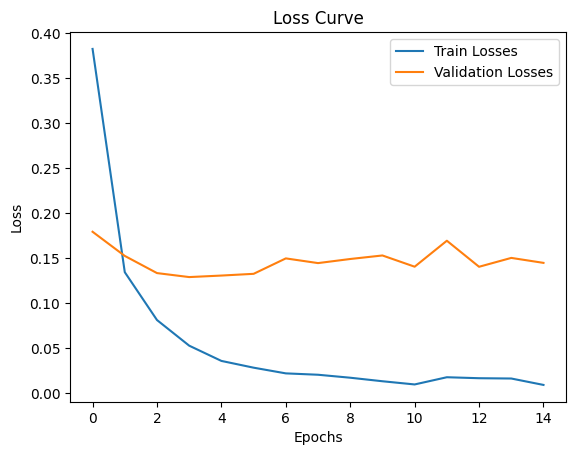

In [ ]:
# YOUR CODE HERE
plt.plot(train_losses,label='Train Losses')
plt.plot(val_losses,label='Validation Losses')
plt.legend()
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss Curve')
plt.show()

### 5.3 Confusion Matrix & Analysis (5 Marks)
1. Plot the confusion matrix using `ConfusionMatrixDisplay`.
2. Write a brief markdown explanation of which ancient character classes are most frequently confused by the model based on the matrix.

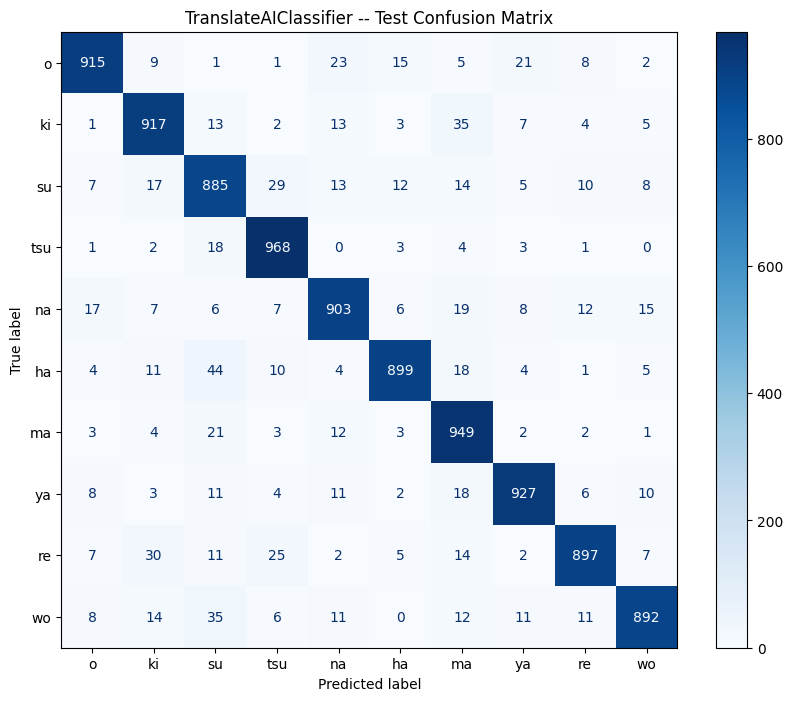

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# YOUR CODE HERE

cm = confusion_matrix(all_labels,all_preds)

fig,ax = plt.subplots(figsize=(10,8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names)
disp.plot(ax=ax,cmap='Blues')
plt.title('TranslateAIClassifier -- Test Confusion Matrix')
plt.show()


*Double-click here to write your analysis*

**Your Analysis:**

# Primary Confusions (Off-Diagonal Peaks):


1.ha misclassified as su (44 instances)

Highest confusion: Out of all off-diagonal entries in the matrix, true instances of ha are misclassified as su most frequently (44 times).

2.ki misclassified as ma (35 instances)

True instances of ki are mistaken as ma 35 times.

3.wo misclassified as su (35 instances)

True instances of wo are mistaken as su 35 times.

4.re misclassified as ki (30 instances)

True instances of re are mistaken as ki 30 times.

5.su misclassified as tsu (29 instances)

True instances of su are mistaken as tsu 29 times.

6.re misclassified as tsu (25 instances)

True instances of re are mistaken as tsu 25 times.

